# Appendix 1: BaseRecalibrator without a known variant set (bootstrapping)
*INRAe-IFB-INSERM Bioinformatics School 2026*

* Maria BERNARD - INRAE

This appendix complements section **III.2 BaseRecalibrator** of the main practical session. It covers the case, very common for non-model organisms, where **no known variant set** is available (no dbSNP, no "gold standard" VCF) to provide to `BaseRecalibrator` via `--known-sites`.

source:
* [GATK - BQSR bootstrapping for multiple-sample dataset with no known variants (non-human)](https://gatk.broadinstitute.org/hc/en-us/community/posts/360066050311-BQSR-bootstrapping-for-multiple-sample-dataset-with-no-known-variants-non-human-)
* [GATK - Base Quality Score Recalibration (BQSR)](https://gatk.broadinstitute.org/hc/en-us/articles/360035890531-Base-Quality-Score-Recalibration-BQSR)
* [NYU Gencore - Variant calling pipeline GATK4](https://gencore.bio.nyu.edu/variant-calling-pipeline-gatk4/)
* [Sydney Informatics Hub - Bootstrapping for BQSR](https://github.com/Sydney-Informatics-Hub/Bootstrapping-for-BQSR)


## I - Why it is not so simple

As a reminder (see main practical session), `BaseRecalibrator` builds an error model by comparing the observed bases at positions of the genome **assumed to be non-variant**. So as not to learn true biological variants as if they were sequencing errors, the tool needs to exclude positions already known to be variant: this is the role of the `--known-sites` option.

<div style="background-color: #fff3cd; border-left: 6px solid #ffc107; color: #856404; padding: 10px; border-radius: 4px;">
    ⚠️Warning<br>
    Without <code>--known-sites</code>, BaseRecalibrator will confuse true variants (real SNPs/indels of the sample) with sequencing noise, and will therefore <strong>over-correct</strong> variant positions by wrongly lowering their quality.
</div>

Official position of GATK support (Broad Institute) on the subject:

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    « We don't have any current BQSR bootstrapping methods or recommendations for when there is no known sites file. » <br>
    — Genevieve Brandt, GATK team, 2021, on the <a href="https://gatk.broadinstitute.org/hc/en-us/community/posts/360066050311-BQSR-bootstrapping-for-multiple-sample-dataset-with-no-known-variants-non-human-">GATK forum</a>.
</div>

In other words: there is no official "turnkey" procedure. The community has nevertheless converged on an empirical approach called **bootstrapping**, documented in particular in the [historical GATK FAQ on BQSR](https://gatk.broadinstitute.org/hc/en-us/articles/360035890531-Base-Quality-Score-Recalibration-BQSR):

> « First do an initial round of variant calling on your original, unrecalibrated data. Then take the variants that you have the highest confidence in and use that set as the database of known variants by feeding it as a VCF file to the BaseRecalibrator. Finally, do a real round of variant calling with the recalibrated data. These steps could be repeated several times until convergence. »

<div style="background-color: #dafbe1; border-left: 6px solid #1f883d; padding: 10px;">
    💡 <strong>Tip</strong><br>
    On small datasets, or when sequencing depth is low, it is also reasonable <strong>not to perform BQSR at all</strong> and to rely solely on "hard" filtering of the variants after calling. This is a pipeline choice that should be documented.
</div>


## II - General principle: bootstrapping

The idea is to **build yourself** a set of "known" variants from your own data, then refine it through successive iterations, until recalibration no longer brings any notable improvement (convergence).

General scheme (to be followed in this appendix):


```
               initial BAM
                     │
                     ▼
              HaplotypeCaller
                     │
                     ▼
             hard filtering ( "known variants") ◄------------------------------─┐
                     │                                                          │
                     ▼                                                          │
             BaseRecalibrator (recal.table1) ---► AnalyzeCovariates             │
                     │                                      ▲                   │
                     ▼                                      │                   │
            ApplyBQSR (recalibrated BAM) ---► BaseRecalibrator (recal.table2)   │
                     │                                                          │
                     ▼                                                          │
              HaplotypeCaller --------------------------------------------------┘
```

In summary, each cycle (*round*) includes:
1. **HaplotypeCaller** on the BAM (not recalibrated in the 1st round, recalibrated afterwards) → raw VCF
2. **Hard filtering** of this raw VCF → set of "high-confidence" variants = our pseudo `known-sites`
3. **BaseRecalibrator** (`recal.table1`) with this `known-sites` + **AnalyzeCovariates**
4. **ApplyBQSR** → recalibrated BAM
5. **BaseRecalibrator** a second time on the recalibrated BAM (`recal.table2`), to assess the effect of the recalibration
6. **AnalyzeCovariates** (`recal.table1` vs `recal.table2`) → before/after report
7. Loop: the BAM recalibrated in step 4 becomes the input of step 1 for the next round, and so on until convergence.

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    In practice, 2 to 3 rounds are usually enough. Beyond that, the improvement becomes negligible (see part V - how to know when to stop).
</div>


## III - Round 1: building a first set of "known variants"

We start again from the same sample as in the main practical session (`milca_40995`), on the same interval `NC_037329.1:90000000-91140000`, but **without ever using** the `Bos_taurus_..._known_snps.vcf.gz` / `..._known_indels.vcf.gz` files provided for the practical session (here they simulate the absence of a public resource).

In [ ]:
module load gatk4/4.6.1.0
module load r/4.5.2
mkdir -p Results/BQSR_bootstrap/round1

### 1. HaplotypeCaller "round 0" (non-recalibrated BAM)

We apply [HaplotypeCaller](https://gatk.broadinstitute.org/hc/en-us/articles/30332006386459-HaplotypeCaller) directly on the duplicate-marked BAM, as seen in the main practical session, but **without modifying the quality scores**.


In [ ]:
gatk HaplotypeCaller --java-options '-Xmx8G' \
   --input Results/Alignment/milca_40995_md.bam \
   --input Results/Alignment/milca_40995_md.bam \
   --input Results/Alignment/milca_40995_md.bam \
   --input Results/Alignment/milca_40995_md.bam \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --intervals "NC_037329.1:90000000-91140000" \
   --output Results/BQSR_bootstrap/round1/milca_40995_round0.vcf


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    When working on a cohort of samples, you must follow the procedure as in part III.3.2 of the main practical session (GVCF mode) to generate a multi-sample vcf.
</div>

### 2. Hard filtering: building a "high-confidence" variant set

[SelectVariants](https://gatk.broadinstitute.org/hc/en-us/articles/30332055629723-SelectVariants) is used to separate SNPs and Indels (their quality metrics are not comparable), then [VariantFiltration](https://gatk.broadinstitute.org/hc/en-us/articles/30332002832027-VariantFiltration) applies "hard" thresholds on these metrics to keep only the most reliable variants.

The thresholds below follow the classic Broad Institute recommendations for germline hard filtering:

| Metric | SNPs | Indels | Meaning |
|---|---|---|---|
| `QD` (QualByDepth) | `< 2.0` | `< 2.0` | variant confidence normalised by depth |
| `FS` (FisherStrand) | `> 60.0` | `> 200.0` | strand bias (Phred-scaled) |
| `SOR` (StrandOddsRatio) | `> 3.0` | `> 10.0` | strand bias, alternative to FS |
| `MQ` (RMSMappingQuality) | `< 40.0` | - | mapping quality (root mean square) |
| `MQRankSum` | `< -12.5` | - | MQ comparison ref vs alt |
| `ReadPosRankSum` | `< -8.0` | `< -20.0` | position of the variant within the read, ref vs alt |

<div style="background-color: #fff3cd; border-left: 6px solid #ffc107; color: #856404; padding: 10px; border-radius: 4px;">
    ⚠️Warning<br>
    These thresholds are a generic starting point (human genome, Broad best practices) and <strong>not a universal truth</strong>. On a different genome or coverage depth, it is recommended to look at the actual distribution of these metrics (histograms) before setting your own thresholds (<a href="https://gatk.broadinstitute.org/hc/en-us/articles/360035890471-Hard-filtering-germline-short-variants">GATK4: Hard-filtering germline short variants</a>, <a href="https://github.com/broadinstitute/gatk-docs/blob/master/gatk3-methods-and-algorithms/Understanding_and_adapting_the_generic_hard-filtering_recommendations.md">GATK3: Understanding and adapting the generic hard-filtering recommendations</a>).
</div>


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    When working on a multi-sample VCF, each quality metric (QD, FS, SOR, MQ, ...) is computed taking into account the reads of all samples at a given position: true variants shared between samples (or observed in several individuals) come out with higher confidence, which gives a more reliable and more stable "known-sites" set from one round to the next.<br>
</div>

In [ ]:
# Extract the SNPs
gatk SelectVariants \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0.vcf \
   --select-type-to-include SNP \
   --output Results/BQSR_bootstrap/round1/milca_40995_round0_snps.vcf

# Extract the Indels
gatk SelectVariants \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0.vcf \
   --select-type-to-include INDEL \
   --output Results/BQSR_bootstrap/round1/milca_40995_round0_indels.vcf


In [ ]:
# Hard filtering of SNPs
gatk VariantFiltration \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0_snps.vcf \
   --filter-expression "QD < 2.0"             --filter-name "QD2" \
   --filter-expression "FS > 60.0"             --filter-name "FS60" \
   --filter-expression "MQ < 40.0"             --filter-name "MQ40" \
   --filter-expression "SOR > 3.0"             --filter-name "SOR3" \
   --filter-expression "MQRankSum < -12.5"     --filter-name "MQRankSum-12.5" \
   --filter-expression "ReadPosRankSum < -8.0" --filter-name "ReadPosRankSum-8" \
   --output Results/BQSR_bootstrap/round1/milca_40995_round0_snps_filtered.vcf

# Hard filtering of Indels
gatk VariantFiltration \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0_indels.vcf \
   --filter-expression "QD < 2.0"              --filter-name "QD2" \
   --filter-expression "FS > 200.0"            --filter-name "FS200" \
   --filter-expression "SOR > 10.0"            --filter-name "SOR10" \
   --filter-expression "ReadPosRankSum < -20.0" --filter-name "ReadPosRankSum-20" \
   --output Results/BQSR_bootstrap/round1/milca_40995_round0_indels_filtered.vcf


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    <code>VariantFiltration</code> does not remove variants: it fills in the <code>FILTER</code> column of the VCF (<code>PASS</code> or the name of the triggered filter).<br>
    You then need to select only the <code>PASS</code> variants with <code>SelectVariants --exclude-filtered</code>.
</div>


In [ ]:
# Keep only PASS variants and merge filtered SNPs + Indels into a single "known-sites bootstrap" set
gatk SelectVariants \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0_snps_filtered.vcf \
   --exclude-filtered \
   --output Results/BQSR_bootstrap/round1/milca_40995_bootstrap_snps_pass.vcf

gatk SelectVariants \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --variant Results/BQSR_bootstrap/round1/milca_40995_round0_indels_filtered.vcf \
   --exclude-filtered \
   --output Results/BQSR_bootstrap/round1/milca_40995_bootstrap_indels_pass.vcf

gatk MergeVcfs \
   --INPUT Results/BQSR_bootstrap/round1/milca_40995_bootstrap_snps_pass.vcf \
   --INPUT Results/BQSR_bootstrap/round1/milca_40995_bootstrap_indels_pass.vcf \
   --OUTPUT Results/BQSR_bootstrap/round1/milca_40995_bootstrap_known_sites.vcf


### 3. BaseRecalibrator + AnalyzeCovariates + ApplyBQSR (round 1)

We now use this "home-made" VCF as `--known-sites`, exactly as in the main practical session, running the `BaseRecalibrator` step twice to obtain two tables to compare with [AnalyzeCovariates](https://gatk.broadinstitute.org/hc/en-us/articles/30332003333787-AnalyzeCovariates):
* `recal.table1`: model learned **before** recalibration (on the initial BAM)
* `recal.table2`: model re-learned **after** applying the recalibration (on the recalibrated BAM) — if almost no bias remains to be corrected, this second model should be almost flat.


In [ ]:
gatk BaseRecalibrator --java-options '-Xmx8G' \
   --input Results/Alignment/milca_40995_md.bam \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --known-sites Results/BQSR_bootstrap/round1/milca_40995_bootstrap_known_sites.vcf \
   --intervals "NC_037329.1:90000000-91140000" \
   --output Results/BQSR_bootstrap/round1/milca_40995_recal.table1


In [ ]:
gatk ApplyBQSR --java-options '-Xmx8G' \
   --input Results/Alignment/milca_40995_md.bam \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --bqsr-recal-file Results/BQSR_bootstrap/round1/milca_40995_recal.table1 \
   --intervals "NC_037329.1:90000000-91140000" \
   --output Results/BQSR_bootstrap/round1/milca_40995_recal_round1.bam


In [ ]:
gatk BaseRecalibrator --java-options '-Xmx8G' \
   --input Results/BQSR_bootstrap/round1/milca_40995_recal_round1.bam \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --known-sites Results/BQSR_bootstrap/round1/milca_40995_bootstrap_known_sites.vcf \
   --intervals "NC_037329.1:90000000-91140000" \
   --output Results/BQSR_bootstrap/round1/milca_40995_recal.table2


In [ ]:
gatk AnalyzeCovariates \
   --before-report-file Results/BQSR_bootstrap/round1/milca_40995_recal.table1 \
   --after-report-file  Results/BQSR_bootstrap/round1/milca_40995_recal.table2 \
   --plots-report-file  Results/BQSR_bootstrap/round1/milca_40995_AnalyzeCovariates_round1.pdf


Download the PDF produced and open it: for each covariate (sequencing cycle, dinucleotide context, raw quality), it contains a "reported quality" vs "empirical quality" plot **before** (`before` curve) and **after** (`after` curve) recalibration.

<div style="background-color: #fbefff; border-left: 6px solid #8250df; padding: 10px;">
    <strong>Question</strong><br>
    In your report, is the "after" curve closer to the diagonal (y = x) than the "before" curve, or closer to 0? If so, over which quality range does the gap remain most pronounced?
</div>


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    <code>BaseRecalibrator</code> / <code>ApplyBQSR</code> → remain <strong>per-sample</strong> operations (one BAM = one recalibration), but all recalibrations of the same round share the <strong>same</strong> <code>known-sites</code> file obtained over the whole cohort.
</div>

## IV - Round 2: refining the variant set on the recalibrated BAM

We repeat exactly the same chain of steps (HaplotypeCaller → hard filtering → BaseRecalibrator/ApplyBQSR/BaseRecalibrator → AnalyzeCovariates), but this time **starting from the BAM recalibrated in round 1** (`milca_40995_recal_round1.bam`). Calling relies on quality scores that have already been cleaned up, which generally gives a cleaner set of candidate variants for this second round.


In [ ]:
mkdir -p Results/BQSR_bootstrap/round2

# 1. HaplotypeCaller on the BAM recalibrated in the previous round
gatk HaplotypeCaller --java-options '-Xmx8G' \
   --input Results/BQSR_bootstrap/round1/milca_40995_recal_round1.bam \
   --reference data/genome/Bos_taurus_GCF_002263795.3_ARS-UCD2.0_chr2_chr6.fasta \
   --intervals "NC_037329.1:90000000-91140000" \
   --output Results/BQSR_bootstrap/round2/milca_40995_round1.vcf


Repeat the steps of part III.2 (`SelectVariants` SNP/Indel → `VariantFiltration` → `SelectVariants --exclude-filtered` → `MergeVcfs`) on this new VCF to produce `Results/BQSR_bootstrap/round2/milca_40995_bootstrap_known_sites.vcf`, then rerun `BaseRecalibrator` (x2) / `ApplyBQSR` / `AnalyzeCovariates` simply changing the paths to `round2/`.

For this round 2, you then obtain exactly the same pair of files as in round 1: `recal.table1` (before BQSR) and `recal.table2` (after BQSR), compared with each other by `AnalyzeCovariates` to assess the effect of round 2 — this is the **intra-round** comparison, already seen in part III.3.

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    There is a <strong>second</strong>, complementary comparison that directly answers the question "does the bootstrapping need one more round?": comparing the <code>recal.table1</code> of round 1 with the <code>recal.table1</code> of round 2. Both are "before recalibration" models, but learned on different BAMs (initial BAM in round 1, BAM already recalibrated once in round 2).
</div>


In [ ]:
# INTER-round comparison: has the "before BQSR" model still changed much between round 1 and round 2?
gatk AnalyzeCovariates \
   --before-report-file Results/BQSR_bootstrap/round1/milca_40995_recal.table1 \
   --after-report-file  Results/BQSR_bootstrap/round2/milca_40995_recal.table1 \
   --plots-report-file  Results/BQSR_bootstrap/round2/milca_40995_AnalyzeCovariates_cycle1_vs_cycle2.pdf


<div style="background-color: #dafbe1; border-left: 6px solid #1f883d; padding: 10px;">
    💡 <strong>Tip</strong><br>
    If the curves of this <code>cycle1_vs_cycle2</code> report almost overlap, the "known-sites" set has converged and a round 3 will probably not bring much more. If a clear gap remains, continue the bootstrapping (part VI).
</div>


## V - How many rounds? How can you tell that the variant set is "good enough"?

This is the central question of bootstrapping: there is no absolute rule, but two indicators, both readable in the outputs of `AnalyzeCovariates` and `BaseRecalibrator`, help decide:

1. **The "reported vs empirical quality" curve gets closer to the diagonal** (`y = x`) and flattens from one round to the next.
2. **The residual gap (before/after) decreases then stabilises**: when an additional round brings almost no further improvement, you can stop.
    This residual gap can be computed precisely via the root mean square error (RMSE, which must be computed from the raw data of the AnalyzeCovariates report via the `-csv` option), or estimated by taking the difference between the EmpiricalQuality and EstimatedQReported values provided in the report.


The figures below **illustrate this principle** for teaching purposes (they do not come from an actual run on your data, but reproduce the typical shape of `AnalyzeCovariates` reports as described in the [GATK Workshop slides on BQSR](https://qcb.ucla.edu/wp-content/uploads/sites/14/2016/03/GATKwr12-4-Base_recalibration.pdf), where the RMSE (root mean square deviation between reported quality and empirical quality) typically drops from several units before recalibration to a few tenths after recalibration):


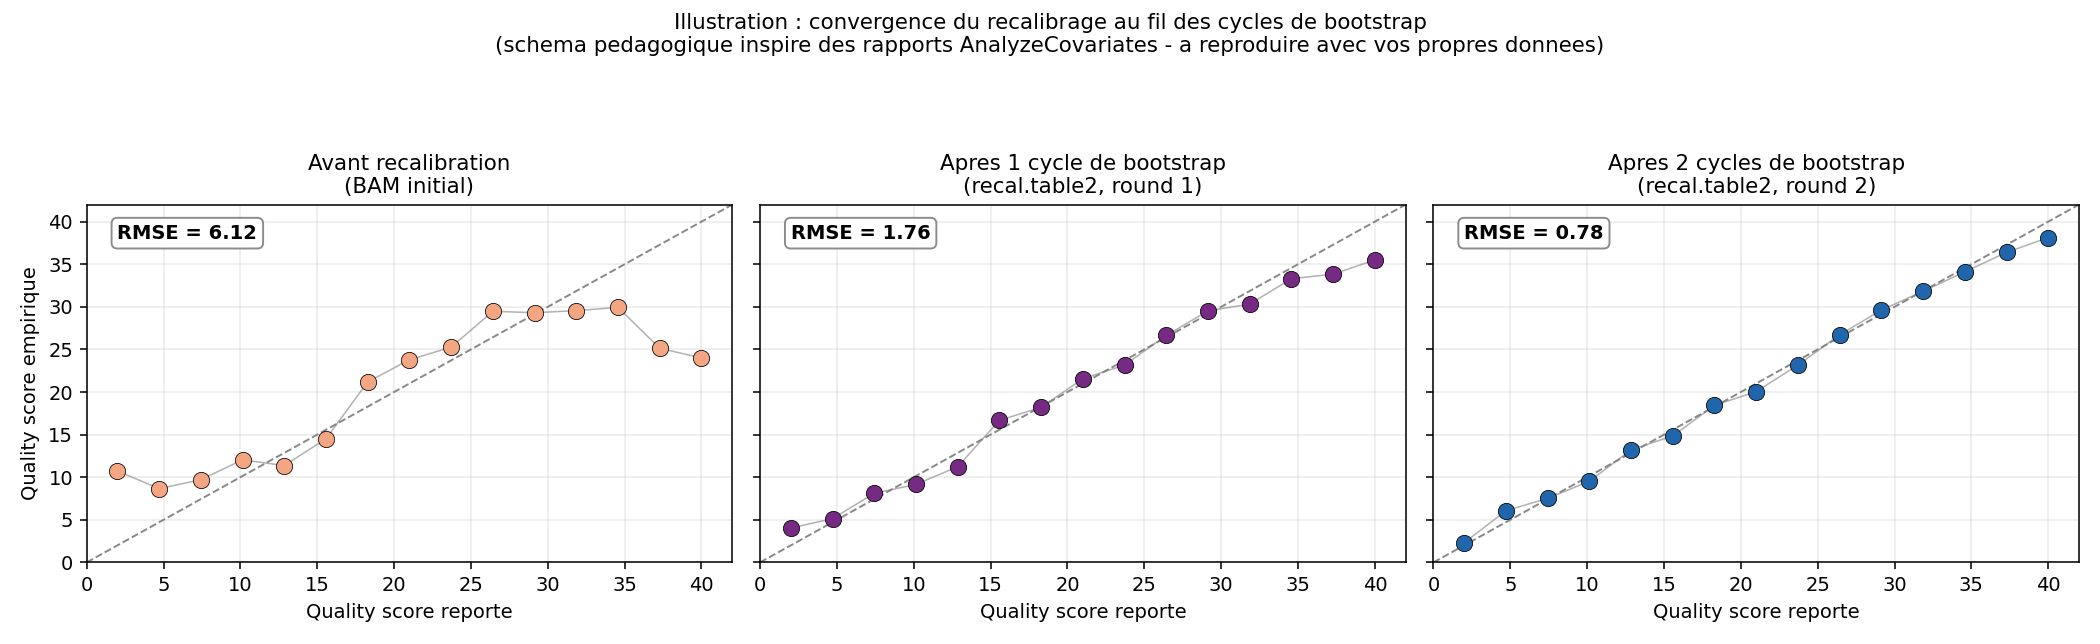


In this illustration:
* **Before recalibration** (initial BAM): the points deviate clearly from the diagonal — the quality score reported by the sequencer is poorly calibrated (high `RMSE`).
* **After 1 bootstrap round**: the points tighten around the diagonal, but a slight gap remains, especially at high qualities.
* **After 2 bootstrap rounds**: the points are almost aligned on the diagonal — a sign that the recalibration model has converged and that the home-made "known-sites" set has become stable.

This convergence can be summarised by tracking the RMSE (or any equivalent deviation metric such as `|EmpiricalQuality - EstimatedQReported|`) over the rounds:


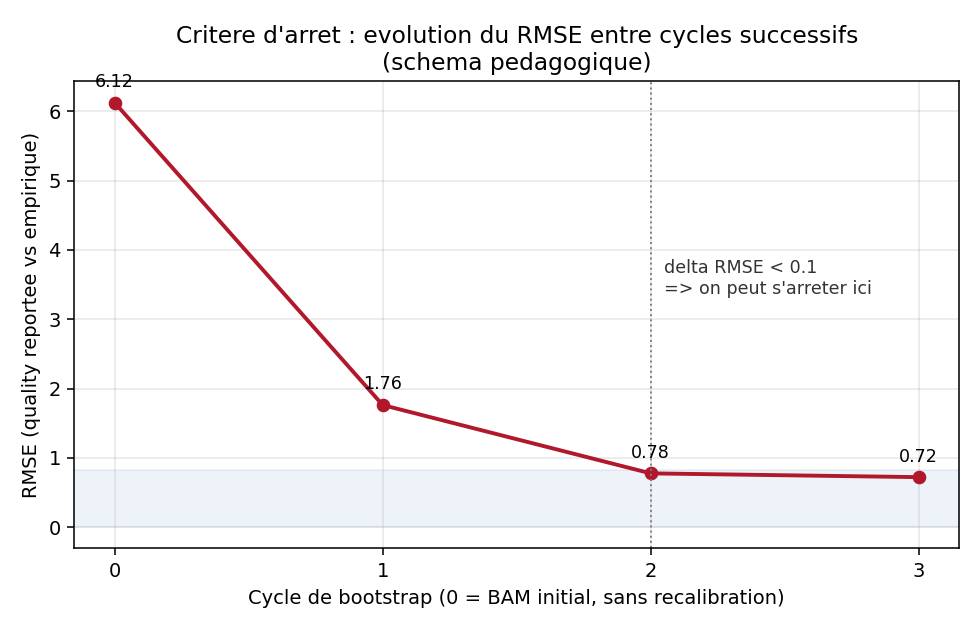


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    In practice, it is often considered that you can stop as soon as the variation in RMSE (or, more simply, the visual appearance of the <code>before</code>/<code>after</code> curves in the AnalyzeCovariates PDF) between two successive rounds becomes negligible — <strong>typically after 2 to 3 rounds</strong> for a given sample. Going further brings almost nothing and consumes computing time.
</div>
<br>
<div style="background-color: #fff3cd; border-left: 6px solid #ffc107; color: #856404; padding: 10px; border-radius: 4px;">
    ⚠️Warning<br>
    This approach remains an <strong>approximation</strong>: the home-made "known-sites" set does not have the reliability of a public database such as dbSNP (it may contain residual false positives, and the chosen hard filtering directly influences the result). Always document in your methods that bootstrapping was performed, with the filtering thresholds used and the number of rounds.
</div>


## VI - What if a public resource does exist after all?

Before embarking on bootstrapping, always check that no curated public variant resource exists for your species or a closely related species: this will spare you this longer and less reliable procedure. A few leads:
* [Ensembl Variation](https://www.ensembl.org/info/genome/variation/species/index.html) (generalist, may require quality filters)
* [NCBI dbSNP](https://www.ncbi.nlm.nih.gov/snp/) and [NCBI dbVar](https://www.ncbi.nlm.nih.gov/dbvar/) (generalist, may require quality filters)
* databases dedicated to your organism (e.g. for cattle: [1000 Bull Genomes Project](https://www.1000bullgenomes.com/))

## VII - References

* [GATK - BaseRecalibrator](https://gatk.broadinstitute.org/hc/en-us/articles/30332011267355-BaseRecalibrator)
* [GATK - ApplyBQSR](https://gatk.broadinstitute.org/hc/en-us/articles/30331973217435-ApplyBQSR)
* [GATK - AnalyzeCovariates](https://gatk.broadinstitute.org/hc/en-us/articles/30332003333787-AnalyzeCovariates)
* [GATK - Base Quality Score Recalibration (BQSR), historical doc with the bootstrapping procedure](https://gatk.broadinstitute.org/hc/en-us/articles/360035890531-Base-Quality-Score-Recalibration-BQSR)
* [GATK forum - BQSR bootstrapping for multiple-sample dataset with no known variants (non-human)](https://gatk.broadinstitute.org/hc/en-us/community/posts/360066050311-BQSR-bootstrapping-for-multiple-sample-dataset-with-no-known-variants-non-human-)
* [GATK - SelectVariants](https://gatk.broadinstitute.org/hc/en-us/articles/30332055629723-SelectVariants)
* [GATK - VariantFiltration](https://gatk.broadinstitute.org/hc/en-us/articles/30332002832027-VariantFiltration)
* [GATK - Hard-filtering germline short variants](https://gatk.broadinstitute.org/hc/en-us/articles/360035890471-Hard-filtering-germline-short-variants)
* [Gencore NYU - Variant calling pipeline GATK4 (hard filtering thresholds)](https://gencore.bio.nyu.edu/variant-calling-pipeline-gatk4/)
* [Sydney Informatics Hub - Bootstrapping for BQSR (complete pipeline, non-model organisms)](https://github.com/Sydney-Informatics-Hub/Bootstrapping-for-BQSR)
* [GATK Workshop slides - Base Quality Score Recalibration](https://qcb.ucla.edu/wp-content/uploads/sites/14/2016/03/GATKwr12-4-Base_recalibration.pdf)
* [1000 Bull Genomes Project](https://www.1000bullgenomes.com/)
